**Objective of the Practical Session**

The objective of this practical session is to understand and implement full-batch gradient descent for training a neural network, and to study the impact of the step size (learning rate) on optimization performance.

# Practical Session 1

In [1]:
import random
import numpy as np
import torch
import torch.nn as nn
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

SEED=42

def seed_all(seed=SEED):
  random.seed(SEED)
  np.random.seed(SEED)
  torch.manual_seed(SEED)
  torch.cuda.manual_seed_all(SEED)
seed_all()

if not torch.cuda.is_available():
    raise RuntimeError("This practical session requires a CUDA-enabled GPU.")

device = torch.device("cuda")
print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")
print("This practical session is GPU-only.")

PyTorch version: 2.11.0+cu130
Device: cuda
This practical session is GPU-only.


Read carefully the following code block! Everything should be run on the GPU!

In [32]:
# @title Utils for dataloading and simple CNN definition

USE_REGRESSION = False  # True -> MNIST linear regression on even/odd, False -> MNIST CNN classification

SEED = 0
N_TRAIN = 10_000
N_VAL = 5_000
N_TEST = 10_000

# ---- Data: MNIST subset loaded fully in memory ----
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])

train_ds = torchvision.datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
test_ds = torchvision.datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

rng = np.random.default_rng(SEED)
perm = rng.permutation(len(train_ds))
train_idx = perm[:N_TRAIN].tolist()
val_idx = perm[N_TRAIN:N_TRAIN + N_VAL].tolist()


def tensorize_subset(ds, indices, batch_size=1024, num_workers=0):
    loader = DataLoader(
        Subset(ds, indices),
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=torch.cuda.is_available(),
    )
    xs, ys = [], []
    for x, y in loader:
        xs.append(x)
        ys.append(y)
    return torch.cat(xs, dim=0), torch.cat(ys, dim=0)


X_train_cpu, y_train_cpu = tensorize_subset(train_ds, train_idx)
X_val_cpu, y_val_cpu = tensorize_subset(train_ds, val_idx)
X_test_cpu, y_test_cpu = tensorize_subset(test_ds, range(N_TEST))

def task_targets(labels, use_regression=USE_REGRESSION):
    if use_regression:
        return (labels % 2 == 0).float().unsqueeze(1)
    return labels.long()

X_train = X_train_cpu.to(device)
y_train = task_targets(y_train_cpu).to(device)
X_val = X_val_cpu.to(device)
y_val = task_targets(y_val_cpu).to(device)
X_test = X_test_cpu.to(device)
y_test = task_targets(y_test_cpu).to(device)

print("X_train:", tuple(X_train.shape), "y_train:", tuple(y_train.shape))
if USE_REGRESSION:
    print(f"positive rate (even): {y_train.float().mean().item():.4f}")


# ---- Model: a tiny CNN ----
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(64, num_classes),
        )

    def forward(self, x):
        return self.net(x)

# get a new model either for regression or classification.
def new_model(seed=SEED, use_regression=USE_REGRESSION):
    seed_all(seed)
    if use_regression:
        return nn.Sequential(nn.Flatten(), nn.Linear(28 * 28, 1)).to(device)
    return SimpleCNN(num_classes=10).to(device)

# get the right loss.
def make_criterion(use_regression=USE_REGRESSION):
    return nn.MSELoss() if use_regression else nn.CrossEntropyLoss()

X_train: (10000, 1, 28, 28) y_train: (10000,)


In this practical session, your code should handle two settings: **classification** and **regression**.

Start simple: write the code for the MNIST classification task only, with `USE_REGRESSION = False`. Only once you have finished everything and it all works, switch to `USE_REGRESSION = True` and **rerun the whole notebook**.

**Question 1:** Implement a function `top1_accuracy` that computes the **top-1 accuracy** (i.e., the fraction of validation examples for which the model’s highest-scoring predicted class matches the true label) of the model on the validation dataset. In the regression setting (`USE_REGRESSION = True`), you can convert the output `y` of the model into a label using `y >= 0.5`.


In [20]:
@torch.no_grad()
def top1_accuracy(model, xVal, yVal, use_regression=USE_REGRESSION):
    model.eval()
    outputs = model(xVal)
    if not torch.isfinite(outputs).all():
        return float("nan")
    if use_regression:
        preds = (outputs.view(-1) >= 0.5).long()
        targets = yVal.view(-1).long()
    else:
        preds = outputs.argmax(dim=1)
        targets = yVal.view(-1).long()
    return (preds == targets).float().mean().item()



**Question 2:**

Implement a **modular training loop** to train the model given by `new_model()` on `X_train` using **full-batch gradient descent** (i.e., each parameter update uses the *entire* training set, not mini-batches). Train for **500 epochs**.

The implementation must support two possible loss functions:
- **Square loss** when `USE_REGRESSION = True` (regression setting),
- **Cross-entropy loss** when `USE_REGRESSION = False` (classification setting).

The choice of loss should be controlled by the boolean flag `USE_REGRESSION` defined in the previous cell.



In [33]:
def train_one_epoch(model, xb, yb, optimizer, use_regression=USE_REGRESSION):
    model.train()
    optimizer.zero_grad(set_to_none=True)
    outputs = model(xb)
    loss = make_criterion(use_regression)(outputs, yb)
    loss.backward()
    optimizer.step()
    return loss.item()

@torch.no_grad()
def evaluate_loss(model, x, y, use_regression=USE_REGRESSION):
    model.eval()
    return make_criterion(use_regression)(model(x), y).item()

def fit(model, xTrain, yTrain, xVal, yVal, lr=0.01, epochs=500,
        use_regression=USE_REGRESSION, weight_decay=0.0, show_progress=True):
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    for _ in tqdm(range(epochs), disable=not show_progress):
        tr_loss = train_one_epoch(model, xTrain, yTrain, optimizer, use_regression)
        if not np.isfinite(tr_loss):
            break
        va_loss = evaluate_loss(model, xVal, yVal, use_regression)
        va_acc = top1_accuracy(model, xVal, yVal, use_regression)
        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        history["val_acc"].append(va_acc)
    return history
trained_model = new_model()
history = fit(trained_model, X_train, y_train, X_val, y_val)

  0%|          | 0/500 [00:00<?, ?it/s]

**Question 3:** Plot the **training loss** and **validation loss** across epochs for the training procedure from Question 2 for both regression and classification settings.


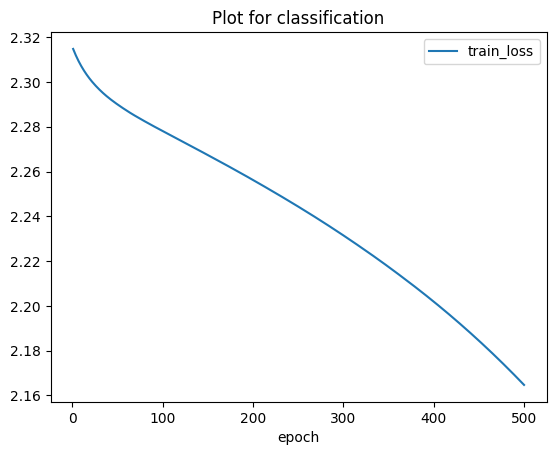

In [34]:
x = np.arange(1, len(history["train_loss"]) + 1)
plt.plot(x, history["train_loss"], label="training loss")
plt.plot(x, history["val_loss"], label="validation loss")

plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.title('Plot for classification')
plt.show()

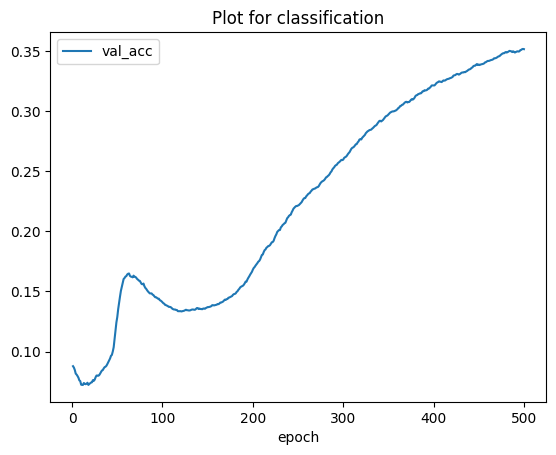

In [35]:
plt.plot(x, history["val_acc"], label ='val_acc')

plt.xlabel("epoch")
plt.legend()
plt.title('Plot for classification')
plt.show()

In [ ]:
USE_REGRESSION = True
y_train = task_targets(y_train_cpu, USE_REGRESSION).to(device)
y_val = task_targets(y_val_cpu, USE_REGRESSION).to(device)
y_test = task_targets(y_test_cpu, USE_REGRESSION).to(device)
trained_model = new_model(use_regression=USE_REGRESSION)
history_regression = fit(trained_model, X_train, y_train, X_val, y_val,
                         use_regression=USE_REGRESSION)

In [ ]:
x = np.arange(1, len(history_regression["train_loss"]) + 1)
plt.plot(x, history_regression["train_loss"], label="training loss")
plt.plot(x, history_regression["val_loss"], label="validation loss")

plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.title('Plot for regression')
plt.show()

plt.plot(x, history_regression["val_acc"], label="validation accuracy")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.legend()
plt.show()

**Question 4:** What do you observe in these training curves?

The training and validation losses should generally decrease as optimization proceeds. A widening gap between them would suggest overfitting; the linear even/odd regression problem is simpler than ten-class CNN classification, so compare the shapes and scales within each task rather than across tasks. The exact curves depend on the selected learning rate and the run.

**Question 5:** Perform a grid search over the learning rates `[3e-3, 3e-2, 0.3, 3.0]`. For each learning rate, train the model (using the same training procedure as in Question 2) and record the **final test accuracy** at the end of training. Again, the plot should be done for both regression and classification settings.


In [ ]:
LEARNING_RATES = [3e-3, 3e-2, 0.3, 3.0]

def run_learning_rate_grid(use_regression, epochs=500):
    y_train_task = task_targets(y_train_cpu, use_regression).to(device)
    y_val_task = task_targets(y_val_cpu, use_regression).to(device)
    y_test_task = task_targets(y_test_cpu, use_regression).to(device)
    results = {}
    for lr in LEARNING_RATES:
        model = new_model(use_regression=use_regression)
        history = fit(model, X_train, y_train_task, X_val, y_val_task,
                      lr=lr, epochs=epochs, use_regression=use_regression,
                      show_progress=False)
        results[lr] = {
            "test_acc": top1_accuracy(model, X_test, y_test_task, use_regression),
            "history": history,
        }
        print(f"lr={lr:g}, final test accuracy={results[lr]['test_acc']:.4f}")
    return results

classification_results = run_learning_rate_grid(use_regression=False)
regression_results = run_learning_rate_grid(use_regression=True)

**Question 6:** Plot the final test accuracies as a function of the learning rate.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, results, title in [
    (axes[0], classification_results, "Classification"),
    (axes[1], regression_results, "Even/odd regression"),
]:
    rates = list(results)
    scores = [results[lr]["test_acc"] for lr in rates]
    ax.plot(rates, scores, marker="o")
    ax.set_xscale("log")
    ax.set_xlabel("learning rate")
    ax.set_ylabel("final test accuracy")
    ax.set_title(title)
    ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

**Question 7:** What do you observe? Comment.

The learning-rate sweep shows the trade-off between slow progress at a small step size and unstable or divergent updates at an overly large step size. Identify the best rate from each panel rather than assuming both tasks share one optimum. The test score is a final held-out metric; use the validation curves for tuning and treat the test comparison as an exercise summary.

**Bonus:** Implement one selected component of the large/full-batch training recipe from https://arxiv.org/pdf/2109.14119 to improve validation accuracy.

In [ ]:
# Explicit weight decay is an L2 regularization component of the full-batch recipe.
best_lr = max(
    LEARNING_RATES,
    key=lambda lr: classification_results[lr]["history"]["val_acc"][-1]
    if classification_results[lr]["history"]["val_acc"]
    and np.isfinite(classification_results[lr]["history"]["val_acc"][-1])
    else -np.inf,
)
y_train_class = task_targets(y_train_cpu, use_regression=False).to(device)
y_val_class = task_targets(y_val_cpu, use_regression=False).to(device)
regularized_model = new_model(use_regression=False)
regularized_history = fit(
    regularized_model, X_train, y_train_class, X_val, y_val_class,
    lr=best_lr, use_regression=False, weight_decay=1e-4,
)
print(f"Baseline validation accuracy at lr={best_lr:g}: "
      f"{classification_results[best_lr]['history']['val_acc'][-1]:.4f}")
print(f"Weight-decay validation accuracy: {regularized_history['val_acc'][-1]:.4f}")
plt.plot(classification_results[best_lr]["history"]["val_acc"],
         label="baseline")
plt.plot(regularized_history["val_acc"], label="weight decay=1e-4")
plt.xlabel("epoch")
plt.ylabel("validation accuracy")
plt.legend()
plt.show()